<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Reconcile a year of Bank Rate changes

**How much did Bank Rate change within a year, and which observations account for
that change?** Use the official daily series **IUDBEDR**, retain a prior-year anchor,
and calculate changes in SQL from the original decimal strings. Reconcile their
sum with the difference between the anchor and final observation.

**Recorded official data, real worker.** The default serves unchanged Bank of
England XML responses captured on **14 November 2026 UTC** through the worker's
existing loopback test transport. These are public source recordings, not synthetic
rates. A separate live mode requests the same historical windows from the official
API with no fallback. Both modes use the actual published remote worker.

These are current-source historical observations, not a reconstruction of what
was known at each past release. Source publication strings retain their original
unspecified timezone. [Official series history](https://www.bankofengland.co.uk/boeapps/database/Bank-Rate.asp)
provides the series' percent convention.

## Choose the year and data mode

`YEAR` is **2023 or 2024**; default **2024**, experiment **2023**. `DATA_MODE` is
**"recorded"** or **"live"**. Live changes the retrieval source, while keeping the
selected historical year. Restart and run all after editing.

Fetch the previous **1–31 December** as an anchor window and the selected
**1 January–31 December** as the analysis window, with inclusive calendar bounds.
They are separate requests because the source's daily-series revision path limits
a request to one year. These are observation dates, not UTC instants.

Bank Rate is expressed in **percent**. A change of **1 percentage point = 100 basis
points (bp)**; a rate of 5% is not 5 bp. The XML unit descriptor may be absent, so
we explicitly use the documented convention for this named series.

In [1]:
YEAR = 2024  # 2023 or 2024, inclusive calendar year
DATA_MODE = "recorded"  # "recorded" or "live"; no fallback between modes

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
os.chdir(NOTEBOOK_DIR)
import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

replay, previous_env, run_at, provenance = configure(YEAR, DATA_MODE)
anchor_start, anchor_end = f"{YEAR - 1}-12-01", f"{YEAR - 1}-12-31"
year_start, year_end = f"{YEAR}-01-01", f"{YEAR}-12-31"
source = f"Source: Bank of England · IUDBEDR · {provenance}"
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-boe-portable-7fhyrvtr/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-boe-portable-7fhyrvtr/pyproject.toml.

## Attach the pinned remote worker

The literal `uvx` location installs Git tag **v0.1.0**, which resolves to
**`f0f6a7e195273a157536e838be0efd5f3655e1e8`**, with the repository's tested SDK,
RPC, Arrow and XML-parser versions. It needs uv and first-run downloads; it does
not require a local worker build or parent checkout.

The helper sets the documented `BOE_API_BASE_URL` only in recorded mode. Live mode
removes inherited endpoint overrides, keeps TLS verification enabled, and honors
an existing trusted `SSL_CERT_FILE` or uses the notebook's pinned CA bundle.
The following discovery call is a curated local index, not a complete series search.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'boe' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with defusedxml==0.7.1 --from git+https://github.com/Query-farm/vgi-boe@v0.1.0 vgi-boe-worker');
SELECT * FROM boe.main.datasets(query := 'IUDBEDR');

,series_code,title,frequency,source_url
0,IUDBEDR,Official Bank Rate,D,https://www.bankofengland.co.uk/boeapps/database/


In [4]:
prose(
    f"**{provenance}**. Execution started **{run_at}**. "
    f"Analysis: **{year_start} through {year_end}**, inclusive; "
    f"anchor search: **{anchor_start} through {anchor_end}**, inclusive. "
    "Retrieval time and the source's publication strings are separate metadata."
)

**Recorded official XML · captured 2026-11-14 UTC**. Execution started **2026-11-14T05:55:44.436259+00:00**. Analysis: **2024-01-01 through 2024-12-31**, inclusive; anchor search: **2023-12-01 through 2023-12-31**, inclusive. Retrieval time and the source's publication strings are separate metadata.

## Fetch bounded windows once

Materialize each worker call before any DataFrame capture. Each response includes
metadata, original numeric strings and publication fields, so no separate metadata
request is needed. The output cap is deliberately above these daily windows and
is checked below; it is not a pagination mechanism.

The recordings preserve source XML byte for byte, with exact query parameters,
retrieval timestamps and SHA-256 hashes in [the manifest](recordings/manifest.json).
A mismatched request or checksum fails explicitly.

In [5]:
%%sql
CREATE TABLE anchor_raw AS SELECT * FROM boe.main.observations(
    ['IUDBEDR'], start_date := '{{anchor_start}}', end_date := '{{anchor_end}}', max_rows := 1000);
CREATE TABLE year_raw AS SELECT * FROM boe.main.observations(
    ['IUDBEDR'], start_date := '{{year_start}}', end_date := '{{year_end}}', max_rows := 1000);
CREATE TABLE raw_observations AS SELECT * FROM anchor_raw UNION ALL SELECT * FROM year_raw;
SELECT DISTINCT series_code, title, frequency, frequency_name, unit_descriptor, description
FROM raw_observations;

,series_code,title,frequency,frequency_name,unit_descriptor,description
0,IUDBEDR,Official Bank Rate,D,Daily,None,Official Bank Rate


## Check coverage before calculating changes

Keep missing values distinct from zero. This reconciliation requires usable
observations throughout the returned rows and a usable anchor; it stops if source
values are missing rather than interpolating them. Dates with no returned row are
reported as unobserved calendar dates, not filled with synthetic daily values.

Parse `value_text` as **DECIMAL(12,6)** and verify that this preserves the source's
precision. The Float64 convenience column is checked against it, but the change
and reconciliation arithmetic below uses DECIMAL.

In [6]:
%%sql quality <<
SELECT count(*) AS returned_rows,
       count(*) = count(DISTINCT observation_date) AS unique_dates,
       bool_and(series_code = 'IUDBEDR' AND title = 'Official Bank Rate' AND frequency = 'D') AS expected_series,
       count(*) FILTER (WHERE value IS NULL OR try_cast(value_text AS DECIMAL(12,6)) IS NULL) AS unavailable_values,
       bool_and(try_cast(value_text AS DECIMAL(38,12)) = try_cast(value_text AS DECIMAL(12,6))) AS exact_decimal,
       max(abs(value - try_cast(value_text AS DECIMAL(12,6))::DOUBLE)) < 1e-12 AS float_agrees,
       (SELECT count(*) FROM anchor_raw) BETWEEN 1 AND 999 AS anchor_present_uncapped,
       (SELECT count(*) FROM year_raw) BETWEEN 1 AND 999 AS year_present_uncapped
FROM raw_observations;

In [7]:
display(quality)
q = quality.iloc[0]
assert q.unavailable_values == 0, "Missing values: do not interpolate them for this reconciliation"
assert all(
    bool(q[k])
    for k in [
        "unique_dates",
        "expected_series",
        "exact_decimal",
        "float_agrees",
        "anchor_present_uncapped",
        "year_present_uncapped",
    ]
), "Source contract changed"
prose(
    "The returned series identity and precision are verified. The nullable XML unit descriptor "
    "is retained as supplied; the **percent** convention comes from the linked official Bank Rate history."
)

,returned_rows,unique_dates,expected_series,unavailable_values,exact_decimal,float_agrees,anchor_present_uncapped,year_present_uncapped
0,273,True,True,0,True,True,True,True


The returned series identity and precision are verified. The nullable XML unit descriptor is retained as supplied; the **percent** convention comes from the linked official Bank Rate history.

## Keep the anchor while taking differences

Select the last returned December observation. Compute `lag()` across the combined
anchor and year rows **before** filtering to the selected year. This gives the first
January observation a real predecessor. Each change is a difference between
successive returned observations, not a claim that every calendar date was sampled.

In [8]:
%%sql
CREATE TABLE rates AS
SELECT observation_date, cast(value_text AS DECIMAL(12,6)) AS rate_pct, value_text, last_updated
FROM raw_observations;
CREATE TABLE anchor AS
SELECT * FROM rates WHERE observation_date < DATE '{{year_start}}'
ORDER BY observation_date DESC LIMIT 1;
CREATE TABLE annual_changes AS
WITH prior AS (
  SELECT *, lag(rate_pct) OVER (ORDER BY observation_date) AS prior_pct,
            lag(observation_date) OVER (ORDER BY observation_date) AS prior_date FROM rates
)
SELECT *, (rate_pct - prior_pct) * 100 AS change_bp,
       (rate_pct - (SELECT rate_pct FROM anchor)) * 100 AS cumulative_bp
FROM prior WHERE observation_date BETWEEN DATE '{{year_start}}' AND DATE '{{year_end}}';
CREATE TABLE change_events AS SELECT * FROM annual_changes WHERE change_bp <> 0;
SELECT observation_date, prior_date, prior_pct, rate_pct, change_bp
FROM change_events ORDER BY observation_date;

,observation_date,prior_date,prior_pct,rate_pct,change_bp
0,2024-08-01,2024-07-31,5.25,5.00,-25.0
1,2024-11-07,2024-11-06,5.00,4.75,-25.0


In [9]:
%%sql summary <<
SELECT count(*) AS observed_dates, min(observation_date) AS first_date, max(observation_date) AS last_date,
       date_diff('day', DATE '{{year_start}}', DATE '{{year_end}}') + 1 - count(*) AS unobserved_calendar_dates,
       (SELECT observation_date FROM anchor) AS anchor_date,
       (SELECT rate_pct FROM anchor) AS anchor_pct,
       arg_max(rate_pct, observation_date) AS final_pct,
       sum(change_bp) AS net_bp, sum(abs(change_bp)) AS gross_bp,
       count(*) FILTER (WHERE change_bp > 0) AS increases,
       count(*) FILTER (WHERE change_bp < 0) AS decreases,
       max(last_updated) AS latest_publication_text
FROM annual_changes;

In [10]:
display(summary)
s = summary.iloc[0]
direction = "rose" if s.net_bp > 0 else "fell" if s.net_bp < 0 else "was unchanged"
prose(
    f"Across **{int(s.observed_dates)} returned dates** in {YEAR}, Bank Rate **{direction} "
    f"by {abs(s.net_bp):.0f} bp net**: **{s.anchor_pct:.2f}%** at the "
    f"**{s.anchor_date:%Y-%m-%d}** anchor to **{s.final_pct:.2f}%** on **{s.last_date:%Y-%m-%d}**. "
    f"There were **{int(s.increases)} increases** and **{int(s.decreases)} decreases**. "
    f"**{int(s.unobserved_calendar_dates)} calendar dates** have no row in this response; "
    "none were imputed. Publication strings above retain the source's unspecified timezone."
)

,observed_dates,first_date,last_date,unobserved_calendar_dates,anchor_date,anchor_pct,final_pct,net_bp,gross_bp,increases,decreases,latest_publication_text
0,254,2024-01-02,2024-12-31,112,2023-12-29,5.25,4.75,-50.0,50.0,0,2,2025-01-02 09:30:00


Across **254 returned dates** in 2024, Bank Rate **fell by 50 bp net**: **5.25%** at the **2023-12-29** anchor to **4.75%** on **2024-12-31**. There were **0 increases** and **2 decreases**. **112 calendar dates** have no row in this response; none were imputed. Publication strings above retain the source's unspecified timezone.

## View the level and its observed changes

The level chart includes the anchor and marks every returned observation. Step
connections guide the eye; they do not add rows. Its vertical axis is zoomed and
labelled in percent. Orange marks increases and blue marks decreases consistently
across the figures.

In [11]:
%%sql daily <<
SELECT observation_date, rate_pct FROM anchor
UNION ALL SELECT observation_date, rate_pct FROM annual_changes ORDER BY observation_date;

In [12]:
%%sql events <<
SELECT observation_date, change_bp, rate_pct FROM change_events ORDER BY observation_date;

/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_49605/2219605503.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.set_xlim(pd.Timestamp(year_start) - pd.Timedelta(days=4), pd.Timestamp(year_end) + pd.Timedelta(days=3))
findfont: Failed to find font weight semibold for Arial, now using 700.


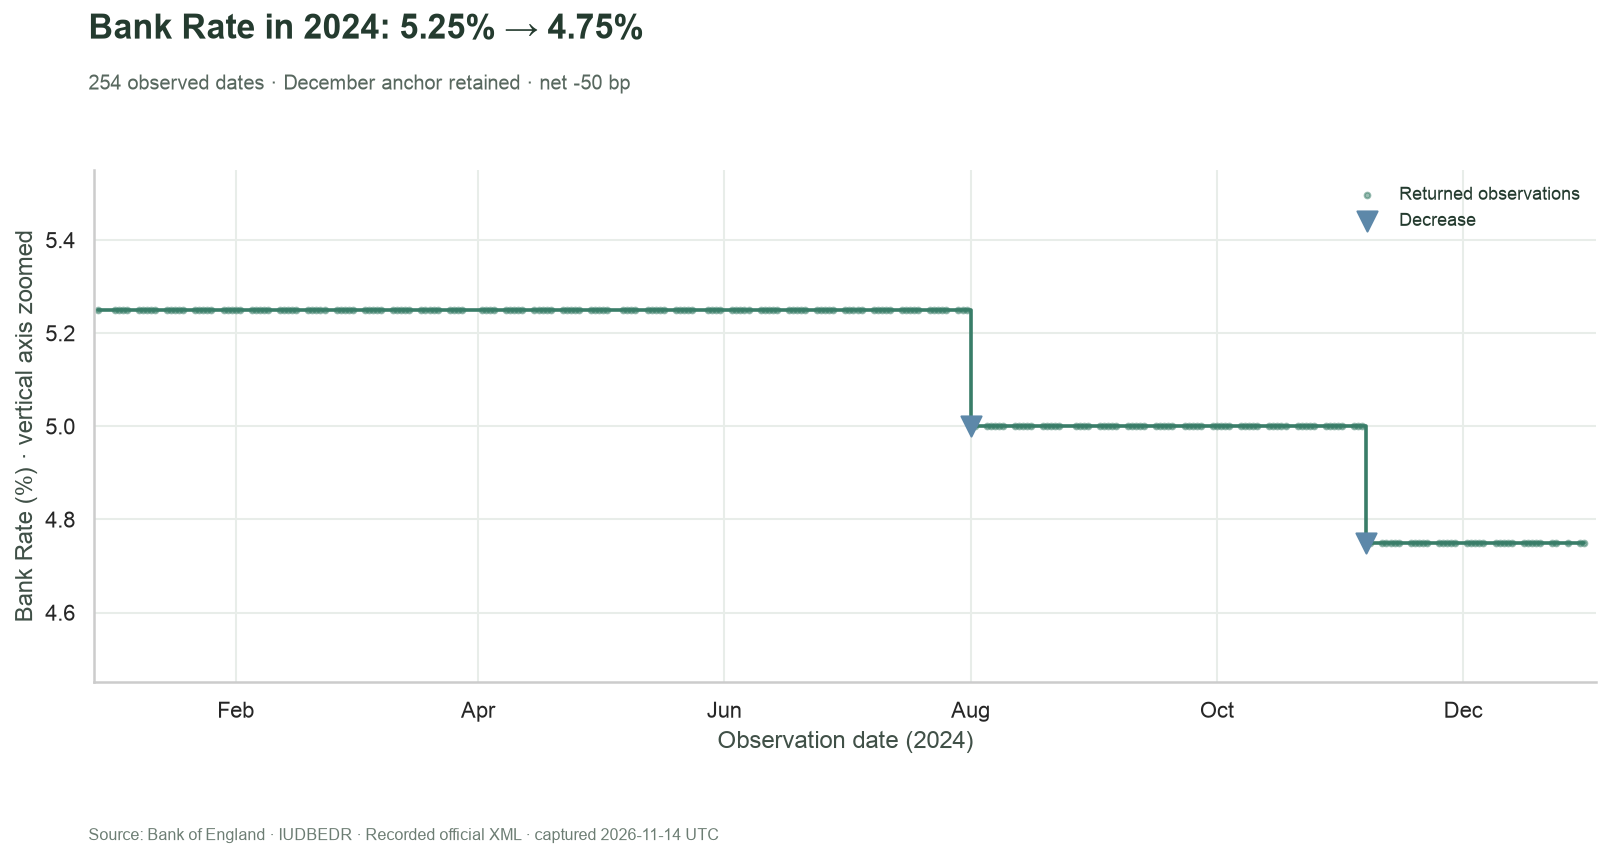

In [13]:
fig, ax = plt.subplots(figsize=(11.5, 6))
ax.step(daily.observation_date, daily.rate_pct, where="post", color="#397D68", linewidth=1.8)
ax.scatter(
    daily.observation_date, daily.rate_pct, color="#397D68", s=8, alpha=0.5, label="Returned observations"
)
for sign, label, color, marker in [(1, "Increase", "#C38738", "^"), (-1, "Decrease", "#5D88A9", "v")]:
    selected = events.loc[events.change_bp * sign > 0]
    if not selected.empty:
        ax.scatter(
            selected.observation_date,
            selected.rate_pct,
            color=color,
            marker=marker,
            s=100,
            label=label,
            zorder=4,
        )
ax.set_ylim(float(daily.rate_pct.min()) - 0.3, float(daily.rate_pct.max()) + 0.3)
ax.set_xlim(pd.Timestamp(year_start) - pd.Timedelta(days=4), pd.Timestamp(year_end) + pd.Timedelta(days=3))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlabel(f"Observation date ({YEAR})")
ax.set_ylabel("Bank Rate (%) · vertical axis zoomed")
ax.legend(loc="best", fontsize=9)
chart(
    fig,
    f"Bank Rate in {YEAR}: {s.anchor_pct:.2f}% → {s.final_pct:.2f}%",
    f"{int(s.observed_dates)} observed dates · December anchor retained · net {s.net_bp:+.0f} bp",
    source,
)

## Attribute the net change to nonzero observations

Each bar is the change from the preceding returned observation, in basis points.
The sum must equal the final rate minus the anchor. Gross movement is the sum of
absolute changes; it can exceed the absolute net movement when directions reverse.
These are changes observed in the series, not separate evidence about announcement
times, reasons or effects on other markets.

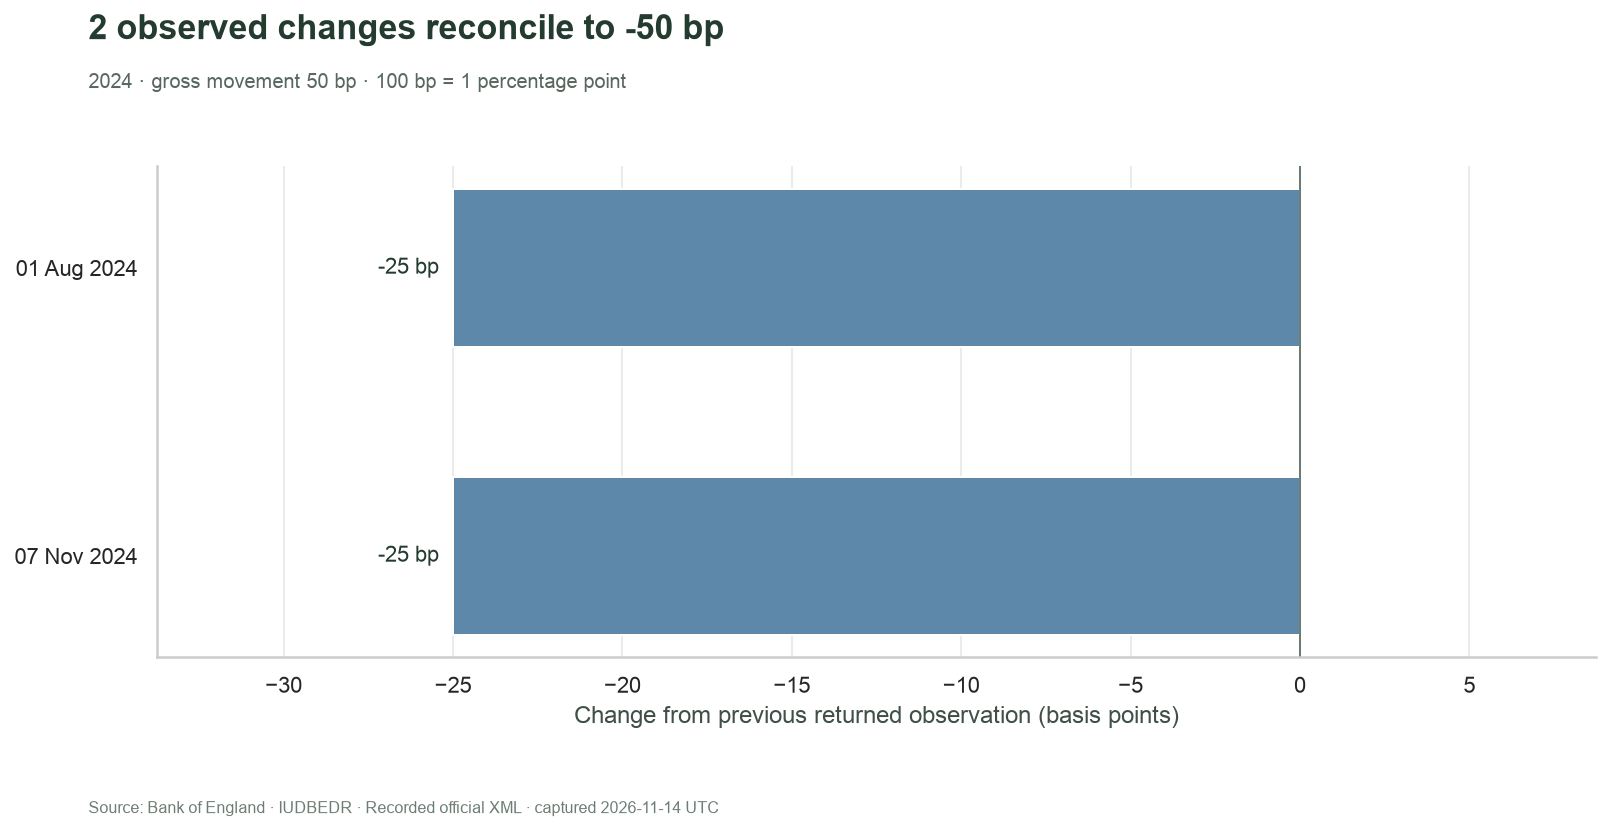

In [14]:
fig, ax = plt.subplots(figsize=(11.5, 5.8))
if events.empty:
    ax.text(0.5, 0.5, "No nonzero changes in the returned observations", transform=ax.transAxes, ha="center")
    ax.set_xlim(-1, 1)
    ax.set_yticks([])
else:
    labels = pd.to_datetime(events.observation_date).dt.strftime("%d %b %Y")
    colors = ["#C38738" if value > 0 else "#5D88A9" for value in events.change_bp]
    bars = ax.barh(labels, events.change_bp, color=colors, height=0.55)
    ax.bar_label(bars, labels=[f"{v:+.0f} bp" for v in events.change_bp], padding=7, fontsize=11)
    ax.invert_yaxis()
    magnitude = max(abs(float(events.change_bp.min())), abs(float(events.change_bp.max())), 1)
    ax.set_xlim(
        min(float(events.change_bp.min()), 0) - magnitude * 0.35,
        max(float(events.change_bp.max()), 0) + magnitude * 0.35,
    )
ax.axvline(0, color="#6C7D73", linewidth=1)
ax.set_xlabel("Change from previous returned observation (basis points)")
ax.grid(axis="y", visible=False)
chart(
    fig,
    f"{len(events)} observed changes reconcile to {s.net_bp:+.0f} bp",
    f"{YEAR} · gross movement {s.gross_bp:.0f} bp · 100 bp = 1 percentage point",
    source,
)

## Verify the exact reconciliation

Use exact DECIMAL equality for the rate arithmetic. The checks cover the anchor,
window, first predecessor, signed sum and cumulative result. They test data
relationships rather than requiring a particular number or direction of changes.

In [15]:
%%sql checks <<
SELECT 'anchor precedes selected year' AS check_name,
       observation_date < DATE '{{year_start}}' AS passed FROM anchor
UNION ALL SELECT 'annual rows inside selected year', bool_and(
       observation_date BETWEEN DATE '{{year_start}}' AND DATE '{{year_end}}') FROM annual_changes
UNION ALL SELECT 'first observation uses anchor predecessor',
       (SELECT prior_pct FROM annual_changes ORDER BY observation_date LIMIT 1) = (SELECT rate_pct FROM anchor)
UNION ALL SELECT 'sum of changes equals endpoint difference',
       sum(change_bp) = (arg_max(rate_pct, observation_date) - (SELECT rate_pct FROM anchor)) * 100 FROM annual_changes
UNION ALL SELECT 'nonzero events preserve signed sum',
       coalesce((SELECT sum(change_bp) FROM change_events),0) = (SELECT sum(change_bp) FROM annual_changes)
UNION ALL SELECT 'cumulative endpoint equals signed sum',
       arg_max(cumulative_bp,observation_date) = sum(change_bp) FROM annual_changes
UNION ALL SELECT 'gross movement bounds absolute net', sum(abs(change_bp)) >= abs(sum(change_bp)) FROM annual_changes;

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "A rate reconciliation relationship failed"
if replay:
    assert sorted(replay.requests) == [f"{YEAR}-anchor", f"{YEAR}-year"], (
        "Each recording should be requested once"
    )
prose(
    f"**All {len(checks)} exact SQL relationships passed.** "
    "The original decimal strings support the calculations; "
    "each bounded API result was materialized once. "
    "This validates the returned series; it does not turn current-source history into a vintage archive."
)

,check_name,passed
0,anchor precedes selected year,True
1,annual rows inside selected year,True
2,first observation uses anchor predecessor,True
3,sum of changes equals endpoint difference,True
4,nonzero events preserve signed sum,True
5,cumulative endpoint equals signed sum,True
6,gross movement bounds absolute net,True


**All 7 exact SQL relationships passed.** The original decimal strings support the calculations; each bounded API result was materialized once. This validates the returned series; it does not turn current-source history into a vintage archive.

## Experiment: compare the preceding year

Change **`YEAR = 2024` to `YEAR = 2023`**, keep **`DATA_MODE = "recorded"`**, restart,
and run all. Predict that the balance of observed increases and decreases changes.
Compare the signed net movement, gross movement, event bars and prior-December
anchor. Axes adapt to the selected data; compare labelled values across runs.

The two years are separate historical windows, not a forecast or a causal
comparison. Restore **2024** for the default. The [guide](README.md) gives separate
experiment and live commands that preserve the saved successful default.

Data: Bank of England, copyright the Governor and Company of the Bank of England,
reused under the [Open Government Licence v3.0](https://www.nationalarchives.gov.uk/doc/open-government-licence/version/3/).
See [database terms](https://www.bankofengland.co.uk/legal#bank-of-england-database).
The notebook's calculations and presentation do not imply Bank endorsement.

In [17]:
con.close()
cleanup(replay, previous_env)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)